# 🤖 Étape 5 : Machine learning non supervisé (Isolation Forest)

**La question :** peut-on repérer les écritures suspectes **sans écrire de règles** et **sans connaître la correction** ?

### Supervisé ou non supervisé ?
- En **apprentissage supervisé**, on montre au modèle des milliers d'exemples étiquetés « fraude » / « normal ». En audit, c'est rarement possible : les fraudes sont **rares**, **rarement documentées** et **toujours différentes**.
- En **apprentissage non supervisé**, le modèle apprend seul à quoi ressemble une écriture **normale**, puis signale celles qui s'en écartent. C'est l'approche adaptée à l'audit.

### L'Isolation Forest en une image
L'algorithme découpe les données au hasard, encore et encore. Une écriture **banale** est entourée de milliers d'écritures semblables : il faut beaucoup de découpes pour l'isoler. Une écriture **atypique** est isolée en quelques découpes. **Moins il faut de découpes, plus le score d'anomalie est élevé.**

Plan :
1. Décrire chaque écriture par des variables
2. Entraîner le modèle et lire les écritures les plus atypiques
3. Évaluer avec la correction, et comparer aux règles de l'étape 3
4. Prendre du recul sur les limites

> Le code est dans [`src/modele_anomalies.py`](../src/modele_anomalies.py).

## 1. Décrire chaque écriture par des variables

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RACINE = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(RACINE / "src"))
from chargement import charger_fec
import modele_anomalies as ma

FIGURES = RACINE / "reports" / "figures"
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 100})
pd.options.display.float_format = lambda x: f"{x:,.2f}".replace(",", " ")
pd.options.display.max_colwidth = 120

def sauver(fig, nom):
    fig.savefig(FIGURES / f"{nom}.png", dpi=120, bbox_inches="tight")

fec = charger_fec()
variables, ecr = ma.construire_variables(fec)
print(f"{variables.shape[0]:,} écritures décrites par {variables.shape[1]} variables".replace(",", " "))

6 654 écritures décrites par 16 variables


Les variables reprennent les **dimensions qu'un auditeur regarde naturellement**, sans viser une fraude en particulier. Elles décrivent **le montant**, **la date**, **le circuit de validation**, **la nature comptable** et **le comportement du tiers** :

In [2]:
pd.DataFrame({"description": ma.DESCRIPTION_VARIABLES}).rename_axis("variable")

,description
variable,
log_montant,Montant de l'écriture (échelle logarithmique)
ecart_montant_schema,Écart du montant par rapport aux écritures du même type
montant_rond,Montant multiple de 100 € sans centimes
jour_non_ouvre,Date un week-end ou un jour férié
jours_avant_cloture,Nombre de jours avant le 31/12
delai_validation,Jours entre la date et la validation
rarete_schema,Rareté de la combinaison de comptes
desequilibre,Écart débit - crédit (log)
nb_meme_piece,Écritures portant le même tiers et la même pièce


In [3]:
variables.describe().T[["mean", "std", "min", "50%", "max"]]

,mean,std,min,50%,max
log_montant,2.99,0.53,1.26,2.98,5.15
ecart_montant_schema,0.79,0.61,0.00,0.66,3.49
montant_rond,0.01,0.09,0.00,0.00,1.00
jour_non_ouvre,0.00,0.05,0.00,0.00,1.00
jours_avant_cloture,166.51,103.82,0.00,167.00,363.00
delai_validation,2.70,5.59,0.00,2.00,197.00
rarete_schema,0.68,0.41,0.44,0.54,3.82
desequilibre,0.00,0.05,0.00,0.00,2.80
nb_meme_piece,1.01,0.08,1.00,1.00,2.00
anciennete_tiers,193.04,105.11,0.00,193.00,365.00


💡 Contrairement aux règles de l'étape 3, on ne fixe **aucun seuil** : on ne dit pas « au-delà de 10 jours, c'est suspect ». Le modèle découvre seul ce qui est rare **dans cette entreprise**.

## 2. Entraîner le modèle

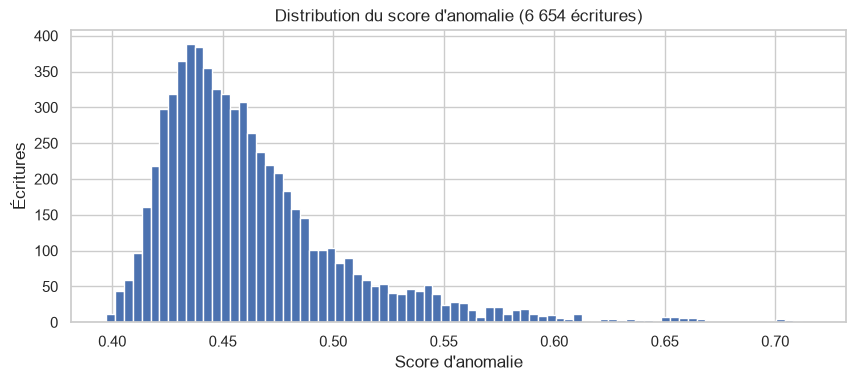

In [4]:
modele, score = ma.entrainer(variables)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(score, bins=80, color="#4C72B0", edgecolor="white")
ax.set(title="Distribution du score d'anomalie (6 654 écritures)", xlabel="Score d'anomalie", ylabel="Écritures")
plt.show()

La grande majorité des écritures ont un score faible et homogène : c'est l'activité courante. Une petite **traîne à droite** regroupe les écritures atypiques. Regardons les 15 premières, avec pour chacune les variables qui la rendent extrême.

In [5]:
def top_explique(score, n=15):
    top = score.sort_values(ascending=False).head(n).index
    return pd.DataFrame({
        "date": ecr.loc[top, "EcritureDate"].dt.strftime("%d/%m/%Y"),
        "libellé": ecr.loc[top, "EcritureLib"],
        "montant": ecr.loc[top, "montant"],
        "score": score.loc[top],
        "pourquoi ?": [" · ".join(ma.expliquer(variables, e)[:3]) for e in top],
    })

top_explique(score)

,date,libellé,montant,score,pourquoi ?
EcritureNum,,,,,
AC000004,02/01/2025,Facture LOYER-2025-01 SCI Les Tilleuls,4 200.00,0.72,Écart du montant par rapport aux écritures du même type : très faible · Montant multiple de 100 € sans centimes · No...
AC000909,01/10/2025,Facture LOYER-2025-10 SCI Les Tilleuls,4 200.00,0.71,Écart du montant par rapport aux écritures du même type : très faible · Montant multiple de 100 € sans centimes · Ra...
AC001108,01/12/2025,Facture LOYER-2025-12 SCI Les Tilleuls,4 200.00,0.71,Écart du montant par rapport aux écritures du même type : très faible · Montant multiple de 100 € sans centimes · Ra...
AC000697,01/08/2025,Facture LOYER-2025-08 SCI Les Tilleuls,4 200.00,0.71,Écart du montant par rapport aux écritures du même type : très faible · Montant multiple de 100 € sans centimes · Ra...
AC001013,03/11/2025,Facture LOYER-2025-11 SCI Les Tilleuls,4 200.00,0.71,Écart du montant par rapport aux écritures du même type : très faible · Montant multiple de 100 € sans centimes · Ra...
AC000121,03/02/2025,Facture LOYER-2025-02 SCI Les Tilleuls,4 200.00,0.71,Écart du montant par rapport aux écritures du même type : très faible · Montant multiple de 100 € sans centimes · Ra...
AC000220,03/03/2025,Facture LOYER-2025-03 SCI Les Tilleuls,4 200.00,0.70,Écart du montant par rapport aux écritures du même type : très faible · Montant multiple de 100 € sans centimes · Ra...
AC000330,01/04/2025,Facture LOYER-2025-04 SCI Les Tilleuls,4 200.00,0.70,Écart du montant par rapport aux écritures du même type : très faible · Montant multiple de 100 € sans centimes · Ra...
AC000519,02/06/2025,Facture LOYER-2025-06 SCI Les Tilleuls,4 200.00,0.70,Écart du montant par rapport aux écritures du même type : très faible · Montant multiple de 100 € sans centimes · Ra...


👉 **Surprise : le haut du classement est occupé par les factures de loyer.** Pour le modèle, elles sont effectivement atypiques : un montant identique tous les mois, un fournisseur unique, un paiement immédiat, un compte peu utilisé…

C'est **le piège classique** de la détection d'anomalies : **atypique ne veut pas dire frauduleux**. On a déjà rencontré ce loyer à l'étape 4 avec Benford.

### Neutraliser les opérations récurrentes connues

Un auditeur procède comme dans la pratique : il identifie les **écritures récurrentes** (loyers, abonnements, honoraires fixes), vérifie leur contrat **une fois**, puis les met de côté. On les repère **sans la correction**, par une définition simple : même tiers, même montant, au moins 6 fois dans l'année.

In [6]:
recurrentes = (ecr.groupby(["tiers", "montant"])["montant"].transform("size") >= 6) & (ecr["tiers"] != "")
print(f"Écritures récurrentes mises de côté : {recurrentes.sum()}")
ecr.loc[recurrentes].groupby("tiers_lib")["montant"].agg(["count", "first"]).rename(
    columns={"count": "écritures", "first": "montant TTC"})

Écritures récurrentes mises de côté : 31


,écritures,montant TTC
tiers_lib,,
Cabinet Expertise Comptable Martin,7,2 880.00
SCI Les Tilleuls,24,4 200.00


In [7]:
score_final = score.copy()
score_final[recurrentes] = score.min()   # placées en fin de liste
top_explique(score_final)

,date,libellé,montant,score,pourquoi ?
EcritureNum,,,,,
OD000017,31/12/2025,Dotation aux amortissements 2025,12 000.00,0.68,Écart du montant par rapport aux écritures du même type : très faible · Montant multiple de 100 € sans centimes · No...
OD000002,20/01/2025,Divers,15 000.00,0.67,Montant de l'écriture (échelle logarithmique) : très élevé · Montant multiple de 100 € sans centimes · Rareté de la ...
AC001000,30/10/2025,Facture F0099-57551 Conseil Stratégie Plus,5 973.10,0.67,Rareté de la combinaison de comptes : très élevé · Variabilité des montants du tiers : très faible · Délai médian de...
OD000003,23/01/2025,Ajustement,7 500.00,0.67,Montant multiple de 100 € sans centimes · Rareté de la combinaison de comptes : très élevé · Jours depuis la premièr...
AC000770,22/08/2025,Facture F0099-78253 Conseil Stratégie Plus,5 933.11,0.67,Rareté de la combinaison de comptes : très élevé · Variabilité des montants du tiers : très faible · Délai médian de...
AC000645,18/07/2025,Facture F0099-54558 Conseil Stratégie Plus,5 952.31,0.67,Rareté de la combinaison de comptes : très élevé · Variabilité des montants du tiers : très faible · Délai médian de...
AC001037,07/11/2025,Facture F0099-30776 Conseil Stratégie Plus,5 750.41,0.66,Rareté de la combinaison de comptes : très élevé · Variabilité des montants du tiers : très faible · Délai médian de...
AC001099,27/11/2025,Facture F0099-85570 Conseil Stratégie Plus,5 853.67,0.66,Rareté de la combinaison de comptes : très élevé · Variabilité des montants du tiers : très faible · Délai médian de...
OD000001,06/01/2025,Divers,5 000.00,0.66,Montant multiple de 100 € sans centimes · Nombre de jours avant le 31/12 : très élevé · Rareté de la combinaison de ...


Le haut du classement change complètement : on y voit maintenant des **opérations diverses aux montants ronds**, des **écritures déséquilibrées**, des **factures au comportement inhabituel**… Le modèle ne sait pas que ce sont des fraudes. Il a simplement repéré qu'elles ne ressemblaient pas au reste.

## 3. Évaluation : on ouvre la correction

Indicateurs :
- **Précision@k et rappel@k** : si l'auditeur examine les *k* écritures au score le plus élevé, quelle part est anormale (précision) et quelle part des anomalies a-t-il trouvée (rappel) ?
- **Average precision** : un résumé global de la qualité du classement. Un classement **au hasard** obtiendrait le taux d'anomalies, soit environ 1,2 %.

In [8]:
anomalies = pd.read_csv(RACINE / "data" / "raw" / "anomalies_injectees.csv")
est_anomalie = pd.Series(variables.index.isin(anomalies["EcritureNum"]), index=variables.index)
type_anomalie = anomalies.set_index("EcritureNum")["type_anomalie"].reindex(variables.index)

courbe = ma.courbe_rappel(score_final, est_anomalie)
courbe.style.format({"précision": "{:.0%}", "rappel": "{:.0%}"})

,anomalies trouvées,précision,rappel
k (écritures examinées),,,
25,23,92%,28%
50,29,58%,36%
91,37,41%,46%
100,37,37%,46%
200,53,26%,65%
300,65,22%,80%
500,71,14%,88%


In [9]:
ap = ma.precision_moyenne(score_final, est_anomalie)
ap_brut = ma.precision_moyenne(score, est_anomalie)
hasard = est_anomalie.mean()
pd.Series({
    "Average precision : modèle brut": f"{ap_brut:.1%}",
    "Average precision : après neutralisation des récurrentes": f"{ap:.1%}",
    "Average precision : classement au hasard": f"{hasard:.1%}",
    "Gain par rapport au hasard": f"× {ap / hasard:.0f}",
}).to_frame("valeur")

,valeur
Average precision : modèle brut,28.4%
Average precision : après neutralisation des récurrentes,47.1%
Average precision : classement au hasard,1.2%
Gain par rapport au hasard,× 39


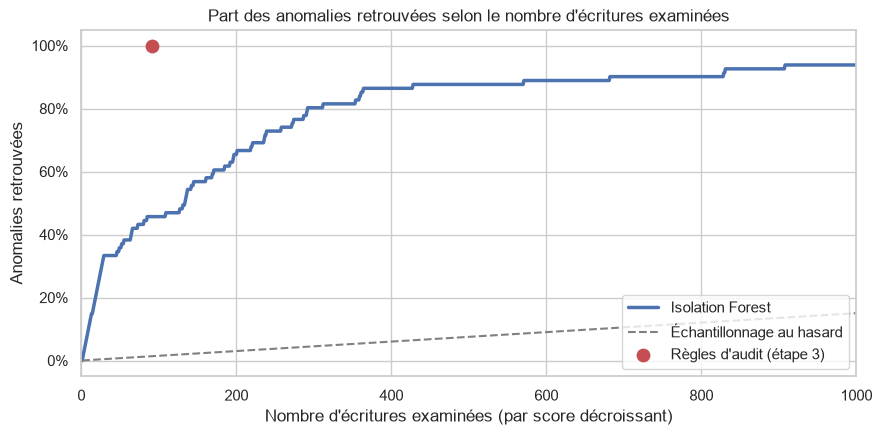

In [10]:
# Courbe : rappel en fonction du nombre d'écritures examinées
ordre = score_final.sort_values(ascending=False).index
rappel_cumule = est_anomalie.loc[ordre].cumsum().values / est_anomalie.sum()
k = np.arange(1, len(ordre) + 1)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(k, rappel_cumule, linewidth=2.5, color="#4C72B0", label="Isolation Forest")
ax.plot(k, k / len(k), linestyle="--", color="grey", label="Échantillonnage au hasard")
ax.scatter([91], [1.0], color="#C44E52", s=80, zorder=5, label="Règles d'audit (étape 3)")
ax.set_xlim(0, 1000)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set(title="Part des anomalies retrouvées selon le nombre d'écritures examinées",
       xlabel="Nombre d'écritures examinées (par score décroissant)", ylabel="Anomalies retrouvées")
ax.legend(loc="lower right")
sauver(fig, "12_courbe_rappel_ml")
plt.show()

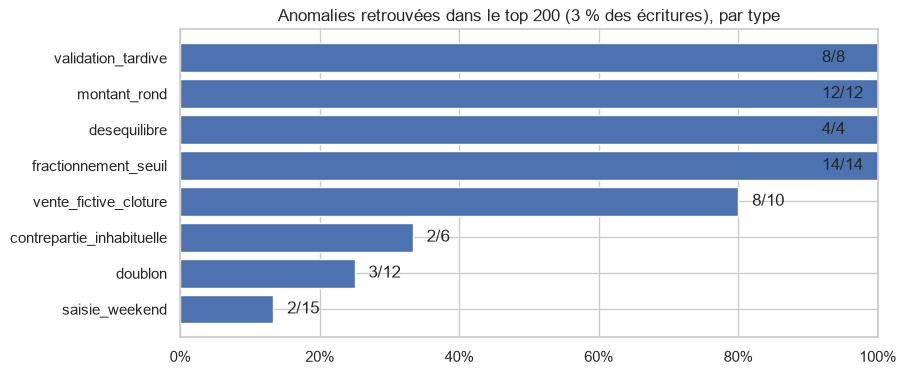

In [11]:
top200 = score_final.sort_values(ascending=False).index[:200]
par_type = pd.DataFrame({
    "anomalies": type_anomalie.value_counts(),
    "dans le top 200": type_anomalie.loc[top200].value_counts(),
}).fillna(0).astype(int)
par_type["rappel"] = par_type["dans le top 200"] / par_type["anomalies"]
par_type = par_type.sort_values("rappel")

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(par_type.index, par_type["rappel"], color="#4C72B0")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_xlim(0, 1)
for i, (n, tot) in enumerate(zip(par_type["dans le top 200"], par_type["anomalies"])):
    ax.text(min(n / tot, 0.9) + 0.02, i, f"{n}/{tot}", va="center")
ax.set(title="Anomalies retrouvées dans le top 200 (3 % des écritures), par type")
sauver(fig, "13_rappel_ml_par_type")
plt.show()

**Lecture :** le modèle excelle sur les anomalies qui rendent l'écriture **globalement atypique** : montants ronds hors des circuits normaux, fournisseur nouveau aux montants répétitifs, écritures déséquilibrées, avoirs validés des mois plus tard, grosses ventes de fin d'année.

Il est **beaucoup plus faible** sur les anomalies qui ne se voient que sur **un seul détail** : une facture banale saisie un samedi, un doublon qui ressemble trait pour trait à l'original. Noyées parmi 15 autres variables, ces particularités pèsent peu. C'est précisément là que les **règles ciblées** sont imbattables.

### Règles, modèle ou les deux ?

Les règles de l'étape 3 signalent 91 écritures. Comparons-les avec les 91 premières écritures du modèle, puis avec une **approche hybride** qui classe les écritures d'abord par nombre d'alertes des règles, puis par score du modèle.

In [12]:
regles = pd.read_csv(RACINE / "data" / "processed" / "ecritures_tests.csv", index_col="EcritureNum")
nb_alertes = regles["nb_alertes"].reindex(variables.index).fillna(0)

def evaluer_top(classement, k=91):
    top = classement.sort_values(ascending=False).index[:k]
    trouvees = int(est_anomalie.loc[top].sum())
    return {"anomalies trouvées": trouvees, "précision": trouvees / k, "rappel": trouvees / est_anomalie.sum()}

percentile_ml = score_final.rank(pct=True)
comparaison = pd.DataFrame({
    "Échantillon au hasard (attendu)": {"anomalies trouvées": round(91 * hasard, 1), "précision": hasard,
                                        "rappel": 91 / len(variables)},
    "Isolation Forest seul": evaluer_top(score_final),
    "Règles d'audit (étape 3)": evaluer_top(nb_alertes + percentile_ml * 1e-6),
}).T
comparaison.style.format({"anomalies trouvées": "{:.0f}", "précision": "{:.0%}", "rappel": "{:.0%}"})

,anomalies trouvées,précision,rappel
Échantillon au hasard (attendu),1,1%,1%
Isolation Forest seul,37,41%,46%
Règles d'audit (étape 3),81,89%,100%


Sur ce jeu de données, **les règles font mieux que le modèle**. Ce n'est pas une surprise : elles ont été écrites **en connaissant les fraudes injectées**, alors que le modèle n'en savait rien. La comparaison juste n'est donc pas « règles contre modèle », mais « **modèle contre échantillonnage au hasard** », qui est la pratique traditionnelle de l'audit : **37 anomalies trouvées contre 1**.

J'ai aussi testé une approche **hybride** (trier les alertes des règles par score du modèle) : elle n'améliore rien ici, car les règles sont déjà précises à environ 97 % sur leurs 30 premières alertes. Je préfère l'écrire plutôt que de présenter un gain qui n'existe pas.

Le vrai rôle du modèle à côté des règles, c'est celui de **filet de sécurité** : les écritures très atypiques **qu'aucune règle n'a signalées**.

In [13]:
top100 = score_final.sort_values(ascending=False).index[:100]
filet = [e for e in top100 if nb_alertes[e] == 0]
print(f"Parmi les 100 écritures les plus atypiques, {len(filet)} n'ont déclenché aucune règle.")
ecr.loc[filet, ["EcritureDate", "EcritureLib", "tiers_lib", "montant"]].assign(
    score=score_final.loc[filet]).head(8)

Parmi les 100 écritures les plus atypiques, 62 n'ont déclenché aucune règle.


,EcritureDate,EcritureLib,tiers_lib,montant,score
EcritureNum,,,,,
AC000081,2025-01-23,Facture TEL-2025-01 TéléCom Pro Services,TéléCom Pro Services,216.96,0.66
AC001109,2025-12-01,Facture TEL-2025-12 TéléCom Pro Services,TéléCom Pro Services,215.38,0.64
AC000217,2025-02-28,Facture TEL-2025-02 TéléCom Pro Services,TéléCom Pro Services,195.16,0.64
AC000921,2025-10-06,Facture TEL-2025-10 TéléCom Pro Services,TéléCom Pro Services,249.62,0.64
AC000367,2025-04-11,Facture TEL-2025-04 TéléCom Pro Services,TéléCom Pro Services,211.49,0.63
BQ003003,2025-12-31,Virement salaires 12/2025,,78 078.00,0.63
AC000308,2025-03-26,Facture TEL-2025-03 TéléCom Pro Services,TéléCom Pro Services,236.65,0.63
BQ000001,2025-01-06,Échéance emprunt 01/2025,,1 200.00,0.63


👉 Ici, ce sont des opérations légitimes et faciles à expliquer : abonnement téléphonique (un fournisseur à part, aux petits montants), virement des salaires de décembre gonflé par le 13e mois, échéances d'emprunt…, puisque les règles couvraient déjà toutes les anomalies injectées. **Sur un vrai dossier, c'est précisément dans cette liste que se cacherait une fraude inédite**, à laquelle personne n'a pensé en écrivant les règles.

**Les deux approches sont donc complémentaires :**
- les **règles** sont redoutables sur les fraudes **connues**, à condition de savoir quoi chercher ;
- le **modèle** trouve une large part des anomalies **sans aucune connaissance préalable**, environ 40 fois mieux que le hasard, et signale l'atypique que les règles ne couvrent pas.

### Le résultat est-il stable ?

L'Isolation Forest fait des découpes **aléatoires**. Un résultat sérieux ne doit pas dépendre du hasard : on réentraîne le modèle avec plusieurs graines aléatoires.

In [14]:
stabilite = {}
for graine in [1, 7, 42, 123, 2025]:
    _, s = ma.entrainer(variables, graine=graine)
    s[recurrentes] = s.min()
    stabilite[graine] = {"average precision": ma.precision_moyenne(s, est_anomalie),
                         "rappel top 200": ma.courbe_rappel(s, est_anomalie, tailles=(200,))["rappel"].iloc[0]}
pd.DataFrame(stabilite).T.rename_axis("graine").style.format("{:.1%}")

,average precision,rappel top 200
graine,,
1,48.0%,66.7%
7,49.3%,67.9%
42,47.1%,65.4%
123,46.3%,63.0%
2025,45.0%,65.4%


## 4. Limites et bonnes pratiques

1. **Atypique ≠ frauduleux** : sans neutralisation des opérations récurrentes, le modèle mettait les loyers en tête. Le jugement de l'auditeur reste indispensable pour **interpréter** chaque alerte.
2. **Le choix des variables compte énormément** : une anomalie qui ne touche aucune variable est invisible. Et ajouter des variables inutiles **dilue** le signal.
3. **Pas d'optimisation sur la correction** : dans la vraie vie, on n'a pas d'étiquettes. Je n'ai donc ni sélectionné les variables ni réglé le modèle en regardant la correction, qui sert **uniquement** à l'évaluation finale. Les résultats sont ainsi représentatifs d'un usage réel.
4. **Explicabilité** : la colonne « pourquoi ? » donne une explication simple, indispensable pour qu'un auditeur fasse confiance au modèle et documente son dossier.

## 5. Sauvegarde des scores

In [15]:
sortie = RACINE / "data" / "processed" / "scores_anomalies.csv"
export = ecr[["JournalCode", "EcritureDate", "PieceRef", "EcritureLib", "tiers_lib", "montant"]].join(
    pd.DataFrame({"score_anomalie": score_final, "recurrente": recurrentes, "nb_alertes_regles": nb_alertes}))
export["raisons"] = [" · ".join(ma.expliquer(variables, e)[:3]) if score_final[e] >= score_final.quantile(0.95) else ""
                     for e in export.index]
export.sort_values("score_anomalie", ascending=False).to_csv(sortie, encoding="utf-8")
print(f"Scores sauvegardés : {sortie.relative_to(RACINE)}")

Scores sauvegardés : data\processed\scores_anomalies.csv


## ✅ Ce qu'il faut retenir

| | Règles (étape 3) | Isolation Forest (étape 5) |
|---|---|---|
| Connaissance préalable nécessaire | Oui : il faut savoir quoi chercher | Non |
| Fraudes connues | ✅ Excellent | 🟡 Bon |
| Fraudes nouvelles | ❌ Invisibles si non codées | ✅ Peut les repérer |
| Anomalies sur un seul détail (date, doublon) | ✅ | ❌ |
| Explicabilité | Immédiate | À construire (colonne « pourquoi ? ») |

**La compétence démontrée :** construire des variables métier, entraîner un modèle non supervisé, l'évaluer honnêtement (précision@k, average precision, comparaison au hasard, stabilité), identifier ses angles morts et le combiner intelligemment avec l'expertise métier.

**Prochaine étape :** rendre tout cela utilisable par un auditeur, avec une **application interactive** qui présente les écritures à risque, les raisons des alertes et les graphiques clés.